# E13-H72 - capped ground cost

**Author**: Konrad Jelen (kj) <br>
**Date**: 2026-10-09 <br>
**Pipeline stage**: experiment - registered hypothesis E13-H72 of the E13 campaign (transport-overflow restrictions), stage A (measure) <br>

Tests one pre-registered toggle over the shipped Statement Mover's Distance (SMD): cap the ground cost of the
semantic solve at `c`, so the solve runs on `min(sqrt(2 - 2cos), c)` in place of `sqrt(2 - 2cos)`
(`src/docdistance/distance.py:43-58`). The marginals, the exact network-simplex solver and the order axis are
unchanged. Nothing under `src/` is edited: the variant is one wrapper in this notebook that calls the shipped
`cost_matrix` and the shipped uniform marginals and applies `np.minimum(cost, c)` before `ot.emd2`.

$$\mathrm{SMD}_c(A, B) = \min_{T \in U(a, b)} \sum_{i,j} T_{ij}\,\min\!\left(\sqrt{2 - 2\cos(x_i, y_j)},\; c\right)$$

**Hypothesis under test** - a statement with no counterpart pays the ground cost to unrelated statements, so the
cost of the same edit depends on unrelated content. With the cap every arc longer than `c` costs `c`. Predicted:
the coefficient of variation (CV) of the SMD increment of one inserted cross-article statement falls by more than
50%, and the ibm panel moves by about 0.003 at most with `V` at `0/24`.

**Readings**

- **V** - ordinality violations: (gold, adversarial) pairs ranked in the wrong order against the anchor, out of 24
- **margin** - `min gold closeness − max adversarial closeness`, in closeness points (closeness × 100)
- **d'** - `(mean adversarial distance − mean gold distance) / pooled std`
- **increment** - `SMD(B, B ⊕ s)`: the distance between a host document `B` and the same document with one statement `s` inserted
- **CV** - `std / mean` (population std) of the increments over the insertion set

## Approach

1. **Kill-gate** - share of insertions whose inserted statement costs more than 0.6 to every host statement, with zero transport solves - below 50% the cap rarely applies and the verdict is `Killed-at-gate`
2. **Harness sanity check** - reproduce the naive panel row on OpenVINO INT8 (margin +4.71, d' 4.68, V 0/24) within 5% - a harness that does not reproduce the baseline cannot score a toggle
3. **Registered experiment** - the capped solve at `c = 0.6` on the ibm panel, the triangle inequality over the 11 summaries, and the insertion set; `c = 0.45` and `c = 0.75` are reported without a bar
4. **Guardrails** - `V`, byte hash of `src/`, default-path `smd` and `order_gap` by `np.array_equal`, identity and symmetry of the capped distance
5. **Verdict** - the registered acceptance bar, applied as written

## Outputs

- `reports/E13-H72-capped-ground-cost-metrics.json` - every measured number, the bar readings and the guardrail readings
- Inline: kill-gate table and histogram, panel table and figure, insertion tables and figure, guardrail table, verdict table

## Environment

No GPU is used. `CUDA_VISIBLE_DEVICES` is set empty before the torch import, so the shipped OpenVINO INT8 mmBERT
encoder and the `sat-3l-sm` segmenter run on CPU. `CI=true` switches the OpenVINO usage telemetry off (DEF-DEPS-11).

In [1]:
import os

os.environ["CUDA_VISIBLE_DEVICES"] = ""  # CPU only - every model of this campaign runs on CPU
os.environ["CUDA_DEVICE_ORDER"] = "PCI_BUS_ID"
os.environ.setdefault("CI", "true")  # OpenVINO usage telemetry off (DEF-DEPS-11)
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["TRANSFORMERS_VERBOSITY"] = "error"
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
os.environ["HF_HUB_DISABLE_TELEMETRY"] = "1"

import sys
import warnings

warnings.filterwarnings("ignore")

import torch

print(f"python {sys.version.split()[0]} at {sys.executable}\ntorch {torch.__version__} | cuda available: {torch.cuda.is_available()} | device: cpu")

python 3.14.8 at /home/lab/workspace/learning/projects/docdistance/.venv/bin/python
torch 2.11.0+cu130 | cuda available: False | device: cpu


## Imports

The shipped `docdistance` functions under test, POT for the exact transport solve, and `rich` / `matplotlib` for
the output. No dataframe library is needed: every table has under 30 rows and is rendered from numpy arrays.

In [2]:
%load_ext autoreload
%autoreload 2

# Standard library
import gzip  # read the saved default-path baseline
import hashlib  # byte hash of src/ for the no-edit guardrail
import json  # fixture files and the metrics file
import random  # seed
import subprocess  # git status for the no-edit guardrail
from importlib import metadata  # installed package versions
from itertools import combinations  # document pairs and triples
from pathlib import Path  # file paths

# Numerics
import numpy as np  # arrays and statistics
import ot  # POT - exact network-simplex transport

# Plotting
import matplotlib.pyplot as plt  # inline figures

# Console output
from rich import print as rprint  # one multiline call per text block
from rich.console import Console, Group  # one render call per table block
from rich.progress import BarColumn, MofNCompleteColumn, Progress, TextColumn, TimeElapsedColumn  # progress bars
from rich.table import Table  # tabular output

# docdistance - the shipped functions under test
from docdistance import __version__ as DD_VERSION  # release stamp
from docdistance.distance import SMD_MAX, _ab, closeness, cost_matrix, opw_gap, smd, transport_plan  # shipped distance core
from docdistance.pipeline import NO_COUNTERPART_COST, DocDistance  # shipped segment + embed path, the 0.6 constant

console = Console()
VERSIONS = {"docdistance": DD_VERSION, "POT": metadata.version("POT"), "openvino": metadata.version("openvino"), "numpy": np.__version__}
print(" | ".join(f"{k} {v}" for k, v in VERSIONS.items()) + f" | SMD_MAX {SMD_MAX:.6f} | NO_COUNTERPART_COST {NO_COUNTERPART_COST}")

docdistance 1.1.5 | POT 0.9.6.post1 | openvino 2026.2.1 | numpy 2.4.6 | SMD_MAX 1.414214 | NO_COUNTERPART_COST 0.6


## Reproducibility

Segmentation, the OpenVINO INT8 encode and the network-simplex solve take no random input. The seed is fixed for
the plotting jitter only.

In [3]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
print(f"SEED = {SEED}")

SEED = 42


## Configuration

Paths, the panel tier map, the bars read from the ledger record `E13-H72`, and the conventions this notebook fixes
before any distance is computed. The bars are applied as written.

- **Hosts** - the 10 base documents of the structure fixture (`meta.json`: 7 ibm gold-tier bases, 3 wergeland bases), statements as stored in `statements.json`
- **Inserted statements** - every statement the shipped default segmentation returns for the other article's source file; markup fragments such as `-` and `##` are statements on that path and are kept
- **Insertion position** - index `n // 2` of the host; SMD does not read statement positions
- **Increment** - `SMD(B, B ⊕ s)`, one value per insertion
- **Registered CV reading** - one CV over all insertions of both directions pooled; the bar is `1 − CV_capped / CV_shipped >= 0.50` at `c = 0.6`
- **Other CV readings, no bar** - each direction alone, the median of the 10 per-host CVs, the increment multiplied by `n + 1` (which removes the host-length factor), and the pool without statements under 5 words
- **Other kill-gate readings, no bar** - each direction alone, statements of 5 or more words, statements under 5 words, the ibm hosts segmented on the shipped path, and unique statements counted when above 0.6 in at least one host
- **Float slack** - `1e-9`, the E12-H66 value, absorbs float64 rounding of the LP objective: a triangle violation is `d(a, b) > d(a, c) + d(c, b) + 1e-9`, and a distance counts as changed by the cap when it differs from shipped by more than `1e-9`

In [4]:
# Paths
ROOT = Path("/home/lab/workspace/learning/projects/docdistance")  # repo root
SUMMARY_DIR = ROOT / "data/interim/exec-summaries/ibm-ai-adoption/summaries"  # ibm 11-summary panel
IBM_SOURCE = ROOT / "data/interim/exec-summaries/ibm-ai-adoption/source/source-article.md"  # inserted into the wergeland hosts
WERG_SOURCE = ROOT / "data/interim/ai-society-wergeland/source/source-article.md"  # inserted into the ibm hosts
FIXTURE_DIR = ROOT / "data/processed/structure-fixture"  # the 10 base documents (hosts)
BASELINE_FILE = ROOT / "reports/E13-campaign/baseline/default-path.json.gz"  # saved 1.1.5 default-path results
METRICS_FILE = ROOT / "reports/E13-H72-capped-ground-cost-metrics.json"  # written by this notebook

# Panel - (filename, label, tier), the E01 / E12-H66 panel
DOCS = [
    ("exec-summary-gold-opus-4-6.md", "gold", "gold"),  # anchor
    ("exec-summary-gold-2-opus-4-6.md", "gold-2", "gold"),
    ("exec-summary-1-opus-4-6.md", "v1", "gold"),
    ("exec-summary-2-opus-4-6.md", "v2", "gold"),
    ("exec-summary-opus-4-6.md", "opus", "gold"),
    ("exec-summary-sonnet-4-6.md", "sonnet", "gold"),
    ("exec-summary-haiku-4-5.md", "haiku", "gold"),
    ("exec-summary-adv1-a-sonnet-4-6.md", "adv1-a", "adv1"),
    ("exec-summary-adv1-b-sonnet-4-6.md", "adv1-b", "adv1"),
    ("exec-summary-adv2-a-haiku-4-5.md", "adv2-a", "adv2"),
    ("exec-summary-adv2-b-haiku-4-5.md", "adv2-b", "adv2"),
]
ANCHOR = "gold"

# Lever - ground-cost cap c on the semantic solve
CAP_REGISTERED = 0.6  # the registered arm
CAPS_UNBARRED = (0.45, 0.75)  # reported without a bar
ARMS = {"shipped": None, **{f"c={c:.2f}": c for c in sorted((CAP_REGISTERED, *CAPS_UNBARRED))}}  # None = shipped smd
REG_ARM = f"c={CAP_REGISTERED:.2f}"

# Kill-gate (record: share of inserted statements whose cheapest cost to the host exceeds 0.6; below 50% ends the run)
GATE_COST = 0.6
GATE_MIN_SHARE = 0.50

# Harness sanity check (record: naive row on OpenVINO INT8, the E12-H66 reading; tolerance 5% relative, V exact)
SANITY_ROW = {"V": 0, "margin_pts": 4.71, "dprime": 4.68}
SANITY_REL_TOL = 0.05

# Acceptance bar (record, applied as written)
BAR_V = 0  # ordinality violations, of 24
BAR_MARGIN_PTS = 4.61  # boundary margin, closeness points
BAR_TRIANGLE = 0  # triangle violations, of 495
BAR_CV_FALL = 0.50  # 1 - CV_capped / CV_shipped over the insertion set

# Conventions fixed before scoring
FLOAT_TOL = 1e-9  # float64 rounding slack of the LP objective: triangle violations and changed-by-the-cap counts (E12-H66 value)
MIN_WORDS = 5  # unbarred reading: the pool without statements under 5 words
DIR_IBM = "ibm host, wergeland statement"  # forward direction
DIR_WERG = "wergeland host, ibm statement"  # reverse direction

# Colours - one palette for every figure
ARM_COLOR = {"shipped": "#3498DB", "c=0.45": "#9B59B6", "c=0.60": "#E74C3C", "c=0.75": "#F39C12"}  # arm
ARM_HATCH = {"shipped": "", "c=0.45": "..", "c=0.60": "//", "c=0.75": "xx"}  # arm, readable without colour
TIER_MARKER = {"gold": "o", "adv1": "s", "adv2": "^"}  # panel tier
DIR_COLOR = {DIR_IBM: "#7F8C8D", DIR_WERG: "#1ABC9C"}  # insertion direction
LEN_COLOR = {"under": "#FD79A8", "atleast": "#8D6E63"}  # inserted statement under / at least MIN_WORDS words
BAR_COLOR = "#2ECC71"  # every registered threshold line

rprint(f"""[bold medium_purple]Configuration[/bold medium_purple]
[dim]{"─" * 60}[/dim]
[bold]Fixture[/bold]
  Panel: [dark_sea_green]{len(DOCS)}[/dark_sea_green] ibm summaries, anchor [cadet_blue]{ANCHOR}[/cadet_blue]
  Hosts: structure-fixture base documents [dim]({FIXTURE_DIR.relative_to(ROOT)})[/dim]
  Inserted statements: the two source articles, shipped default segmentation
  Insertion position: index n // 2

[bold]Lever[/bold]
  Registered arm: cap c = [dark_sea_green]{CAP_REGISTERED}[/dark_sea_green]
  Without a bar: c in [dark_sea_green]{CAPS_UNBARRED}[/dark_sea_green]

[bold]Kill-gate[/bold]
  Share of insertions with cheapest cost to the host > [dark_sea_green]{GATE_COST}[/dark_sea_green] must be >= [dark_sea_green]{GATE_MIN_SHARE:.0%}[/dark_sea_green]

[bold]Harness sanity check[/bold]
  Naive row: V [dark_sea_green]{SANITY_ROW["V"]}/24[/dark_sea_green] exact, margin [dark_sea_green]{SANITY_ROW["margin_pts"]:+.2f}[/dark_sea_green] pts and d' [dark_sea_green]{SANITY_ROW["dprime"]:.2f}[/dark_sea_green] within [dark_sea_green]{SANITY_REL_TOL:.0%}[/dark_sea_green] relative

[bold]Acceptance bar[/bold]
  V = [dark_sea_green]{BAR_V}/24[/dark_sea_green] AND margin >= [dark_sea_green]{BAR_MARGIN_PTS:+.2f}[/dark_sea_green] pts AND triangle violations [dark_sea_green]{BAR_TRIANGLE}/495[/dark_sea_green] AND CV fall >= [dark_sea_green]{BAR_CV_FALL:.0%}[/dark_sea_green]

[bold]Conventions[/bold]
  Float slack: [grey70]{FLOAT_TOL}[/grey70]   Unbarred pool filter: [grey70]{MIN_WORDS}+ words[/grey70]   CV: [grey70]population std / mean[/grey70]
  Device: [dark_sea_green]cpu[/dark_sea_green]

[bold]Output[/bold]
  Metrics: [dim]{METRICS_FILE.relative_to(ROOT)}[/dim]
""")

Configuration
────────────────────────────────────────────────────────────
Fixture
  Panel: 11 ibm summaries, anchor gold
  Hosts: structure-fixture base documents (data/processed/structure-fixture)
  Inserted statements: the two source articles, shipped default segmentation
  Insertion position: index n // 2

Lever
  Registered arm: cap c = 0.6
  Without a bar: c in (0.45, 0.75)

Kill-gate
  Share of insertions with cheapest cost to the host > 0.6 must be >= 50%

Harness sanity check
  Naive row: V 0/24 exact, margin +4.71 pts and d' 4.68 within 5% relative

Acceptance bar
  V = 0/24 AND margin >= +4.61 pts AND triangle violations 0/495 AND CV fall >= 50%

Conventions
  Float slack: 1e-09   Unbarred pool filter: 5+ words   CV: population std / mean
  Device: cpu

Output
  Metrics: reports/E13-H72-capped-ground-cost-metrics.json

## Data loading and embedding

The 11 panel summaries and the two source articles go through the shipped path `DocDistance.embed_statements`
(`_load_body` → `Segmenter.split` → `OpenVINOEncoder.encode`), so they are the documents the library scores. The 10
host documents are the statement lists stored in the structure fixture, embedded with the same shipped encoder.
The byte hash of `src/` is taken here, before any computation, for the no-edit guardrail. No step of this notebook
runs for minutes, so no checkpoint is written.

In [5]:
def tree_hash(root: Path) -> str:
    """SHA-256 over the relative path and bytes of every file under ``root`` (bytecode caches excluded)."""
    digest = hashlib.sha256()
    for path in sorted(root.rglob("*")):
        if path.is_file() and "__pycache__" not in path.parts:
            digest.update(path.relative_to(root).as_posix().encode())
            digest.update(path.read_bytes())
    return digest.hexdigest()


SRC_HASH_BEFORE = tree_hash(ROOT / "src")

dd = DocDistance()  # shipped pipeline, OpenVINO INT8, offline

fixture = json.loads((FIXTURE_DIR / "statements.json").read_text(encoding="utf-8"))
fixture_meta = json.loads((FIXTURE_DIR / "meta.json").read_text(encoding="utf-8"))
IBM_HOSTS, WERG_HOSTS = fixture_meta["ibm_bases"], fixture_meta["werg_bases"]
HOSTS = IBM_HOSTS + WERG_HOSTS

LABELS = [label for _, label, _ in DOCS]
TIER = {label: tier for _, label, tier in DOCS}
STEM = {label: fname.removeprefix("exec-summary-").removesuffix(".md") for fname, label, _ in DOCS}
NONREF = [label for label in LABELS if label != ANCHOR]
GOLD = [label for label in NONREF if TIER[label] == "gold"]
ADV = [label for label in NONREF if TIER[label] != "gold"]
PAIRS = list(combinations(sorted(LABELS, key=STEM.get), 2))  # the 55 pairs, in the argument order of the saved baseline

print(f"src/ hash {SRC_HASH_BEFORE[:16]} | panel {len(LABELS)} documents, {len(GOLD)} gold x {len(ADV)} adversarial = {len(GOLD) * len(ADV)} ordinality pairs | "
      f"{len(PAIRS)} document pairs | hosts {len(IBM_HOSTS)} ibm + {len(WERG_HOSTS)} wergeland")

src/ hash a5932434475fda56 | panel 11 documents, 6 gold x 4 adversarial = 24 ordinality pairs | 55 document pairs | hosts 7 ibm + 3 wergeland


In [6]:
sents, emb = {}, {}  # the 11 panel summaries
pool_sents, pool_emb = {}, {}  # the statements to insert, by source article
host_emb = {}  # the 10 fixture base documents

jobs = (
    [("panel", label, SUMMARY_DIR / fname) for fname, label, _ in DOCS]
    + [("pool", "wergeland", WERG_SOURCE), ("pool", "ibm", IBM_SOURCE)]
    + [("host", host, None) for host in HOSTS]
)
with Progress(TextColumn("{task.description}"), BarColumn(), MofNCompleteColumn(), TimeElapsedColumn()) as progress:
    task = progress.add_task("segment and embed documents", total=len(jobs))
    for kind, name, path in jobs:
        if kind == "panel":
            sents[name], emb[name] = dd.embed_statements(path)
        elif kind == "pool":
            pool_sents[name], pool_emb[name] = dd.embed_statements(path)
        else:
            host_emb[name] = dd.encoder.encode(fixture[name]["statements"])
        progress.advance(task)

In [7]:
tbl = Table(title="Fixture", header_style="bold slate_blue1")
tbl.add_column("role", style="grey70")
tbl.add_column("document")
tbl.add_column("tier / article")
tbl.add_column("statements", justify="right")
for label in LABELS:
    tbl.add_row("panel", label + (" (anchor)" if label == ANCHOR else ""), TIER[label], str(len(emb[label])))
for host in HOSTS:
    tbl.add_row("host", host, fixture[host]["article"], str(len(host_emb[host])))
for name in pool_sents:
    tbl.add_row("inserted pool", f"{name} source", name, str(len(pool_sents[name])))
console.print(tbl)

                             Fixture                              
┏━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┓
┃ role          ┃ document         ┃ tier / article ┃ statements ┃
┡━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━┩
│ panel         │ gold (anchor)    │ gold           │         10 │
│ panel         │ gold-2           │ gold           │         12 │
│ panel         │ v1               │ gold           │         11 │
│ panel         │ v2               │ gold           │         11 │
│ panel         │ opus             │ gold           │         11 │
│ panel         │ sonnet           │ gold           │          9 │
│ panel         │ haiku            │ gold           │         13 │
│ panel         │ adv1-a           │ adv1           │          8 │
│ panel         │ adv1-b           │ adv1           │          9 │
│ panel         │ adv2-a           │ adv2           │          1 │
│ panel         │ adv2-b           │ adv2           │          3 │
│ host          │ gold             │ ibm            │         11 │
│ host          │ gold-2           │ ibm            │         13 │
│ host          │ v1               │ ibm            │         12 │
│ host          │ v2               │ ibm            │         12 │
│ host          │ opus             │ ibm            │         13 │
│ host          │ sonnet           │ ibm            │         11 │
│ host          │ haiku            │ ibm            │         14 │
│ host          │ werg-a           │ wergeland      │         11 │
│ host          │ werg-b           │ wergeland      │         13 │
│ host          │ werg-c           │ wergeland      │         14 │
│ inserted pool │ wergeland source │ wergeland      │         52 │
│ inserted pool │ ibm source       │ ibm            │         70 │
└───────────────┴──────────────────┴────────────────┴────────────┘

## Kill-gate

Runs first and solves no transport problem. For every insertion (host document, inserted statement) the cheapest
ground cost from the inserted statement to any host statement is read from the shipped `cost_matrix`. The gate
reading is the share of insertions where that cheapest cost exceeds 0.6: for those insertions every arc of the
inserted statement is above the registered cap. The record ends the run when the share is below 50%. The rows
marked `no bar` show how the reading depends on the fixture conventions; they do not decide the gate.

In [8]:
rows = []
for direction, hosts, pool in ((DIR_IBM, IBM_HOSTS, "wergeland"), (DIR_WERG, WERG_HOSTS, "ibm")):
    for host in hosts:
        C = cost_matrix(host_emb[host], pool_emb[pool])  # [n_host, n_pool], no transport solve
        for j, text in enumerate(pool_sents[pool]):
            rows.append((direction, host, len(host_emb[host]), pool, j, float(C[:, j].min()), float(C[:, j].mean()), len(text.split())))
INS = {name: np.array(col) for name, col in zip(("direction", "host", "n", "pool", "j", "cheapest", "mean_cost", "words"), zip(*rows))}
N_INS = len(rows)

def gate_row(cheapest: np.ndarray) -> dict:
    """Count, count above the gate cost, share and spread of a set of cheapest costs."""
    return {"n": int(len(cheapest)), "n_above": int((cheapest > GATE_COST).sum()), "share": float((cheapest > GATE_COST).mean()),
            "min": float(cheapest.min()), "median": float(np.median(cheapest)), "max": float(cheapest.max())}


GATE_READING = "all insertions (the gate reading)"
LONG = INS["words"] >= MIN_WORDS  # inserted statement of MIN_WORDS words or more
# the same insertions with the 7 ibm hosts read from the summary files on the shipped path (title line dropped)
shipped_host_cheapest = np.concatenate([cost_matrix(emb[host], pool_emb["wergeland"]).min(0) for host in IBM_HOSTS] + [INS["cheapest"][INS["direction"] == DIR_WERG]])
# per unique inserted statement: its largest cheapest cost over the hosts it enters
per_statement_max = np.array([INS["cheapest"][(INS["pool"] == pool) & (INS["j"] == j)].max() for pool, j in sorted(set(zip(INS["pool"].tolist(), INS["j"].tolist())))])
GATE = {
    DIR_IBM: gate_row(INS["cheapest"][INS["direction"] == DIR_IBM]),
    DIR_WERG: gate_row(INS["cheapest"][INS["direction"] == DIR_WERG]),
    GATE_READING: gate_row(INS["cheapest"]),
    f"statements of {MIN_WORDS}+ words (no bar)": gate_row(INS["cheapest"][LONG]),
    f"statements under {MIN_WORDS} words (no bar)": gate_row(INS["cheapest"][~LONG]),
    "ibm hosts segmented on the shipped path (no bar)": gate_row(shipped_host_cheapest),
    "unique statements, above in at least one host (no bar)": gate_row(per_statement_max),
}
GATE_SHARE = GATE[GATE_READING]["share"]
GATE_PASSED = bool(GATE_SHARE >= GATE_MIN_SHARE)
SHORT_TEXTS = {pool: sorted({text for text in pool_sents[pool] if len(text.split()) < MIN_WORDS}) for pool in pool_sents}

tbl = Table(title=f"Kill-gate - cheapest cost from the inserted statement to its host, against {GATE_COST}", header_style="bold slate_blue1",
            caption=f"gate: share >= {GATE_MIN_SHARE:.0%} - reading {GATE_SHARE:.1%} - {'PASSED' if GATE_PASSED else 'NOT PASSED'}")
tbl.add_column("insertions", style="grey70")
for col in ("count", f"above {GATE_COST}", "share", "min", "median", "max"):
    tbl.add_column(col, justify="right")
for name, g in GATE.items():
    tbl.add_row(name, str(g["n"]), str(g["n_above"]), f"{g['share']:.1%}", f"{g['min']:.3f}", f"{g['median']:.3f}", f"{g['max']:.3f}")
short_listing = f"[bold slate_blue1]Inserted statements under {MIN_WORDS} words, unique texts[/bold slate_blue1]\n" + "\n".join(
    f"  {pool} source ({sum(len(text.split()) < MIN_WORDS for text in pool_sents[pool])} of {len(pool_sents[pool])} statements): "
    + " | ".join(text.replace("[", r"\[") for text in SHORT_TEXTS[pool]) for pool in pool_sents)
console.print(Group(tbl, short_listing))

                Kill-gate - cheapest cost from the inserted statement to its host, against 0.6                 
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━┳━━━━━━━━━━━┳━━━━━━━┳━━━━━━━┳━━━━━━━━┳━━━━━━━┓
┃ insertions                                             ┃ count ┃ above 0.6 ┃ share ┃   min ┃ median ┃   max ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━╇━━━━━━━━━━━╇━━━━━━━╇━━━━━━━╇━━━━━━━━╇━━━━━━━┩
│ ibm host, wergeland statement                          │   364 │        70 │ 19.2% │ 0.398 │  0.480 │ 1.174 │
│ wergeland host, ibm statement                          │   210 │       102 │ 48.6% │ 0.345 │  0.587 │ 1.218 │
│ all insertions (the gate reading)                      │   574 │       172 │ 30.0% │ 0.345 │  0.489 │ 1.218 │
│ statements of 5+ words (no bar)                        │   420 │        22 │  5.2% │ 0.345 │  0.461 │ 0.694 │
│ statements under 5 words (no bar)                      │   154 │       150 │ 97.4% │ 0.585 │  1.125 │ 1.218 │
│ ibm hosts segmented on the shipped path (no bar)       │   574 │       186 │ 32.4% │ 0.345 │  0.493 │ 1.258 │
│ unique statements, above in at least one host (no bar) │   122 │        48 │ 39.3% │ 0.386 │  0.510 │ 1.218 │
└────────────────────────────────────────────────────────┴───────┴───────────┴───────┴───────┴────────┴───────┘
                                gate: share >= 50% - reading 30.0% - NOT PASSED                                
Inserted statements under 5 words, unique texts
  wergeland source (10 of 52 statements): ## | ## Bias and data | ## Future | --> | AI in Society | Faithful to the
| Provenance: data/external/FINAL-Impact-of-AI-on-society_origin.md. | Teaching the topic | source text.
  ibm source (28 of 70 statements): ## | ## Key findings | ## Methodology | ### | - | About IBM | Overview | 
Source: IBM. | Trustworthy and governed AI | Workforce impact

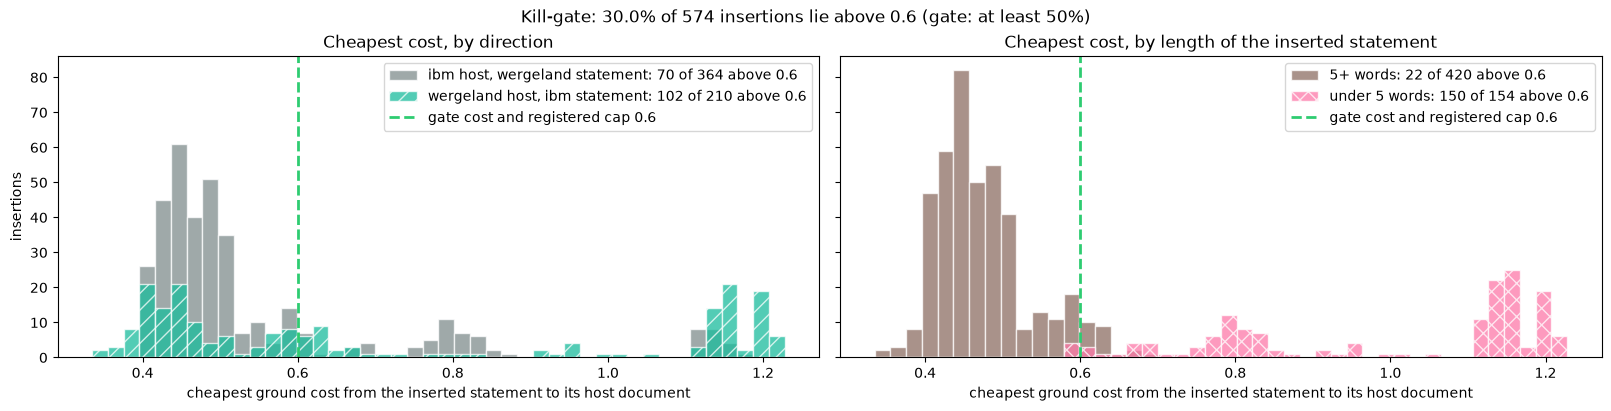

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4), constrained_layout=True, sharey=True)
bins = np.linspace(INS["cheapest"].min() - 0.01, INS["cheapest"].max() + 0.01, 45)
panels = (
    (axes[0], "by direction", ((INS["direction"] == DIR_IBM, DIR_COLOR[DIR_IBM], "", DIR_IBM), (INS["direction"] == DIR_WERG, DIR_COLOR[DIR_WERG], "//", DIR_WERG))),
    (axes[1], "by length of the inserted statement", ((LONG, LEN_COLOR["atleast"], "", f"{MIN_WORDS}+ words"), (~LONG, LEN_COLOR["under"], "xx", f"under {MIN_WORDS} words"))),
)
for ax, title, groups in panels:
    for mask, color, hatch, label in groups:
        ax.hist(INS["cheapest"][mask], bins=bins, color=color, alpha=0.75, hatch=hatch, edgecolor="white",
                label=f"{label}: {int((INS['cheapest'][mask] > GATE_COST).sum())} of {int(mask.sum())} above {GATE_COST}")
    ax.axvline(GATE_COST, color=BAR_COLOR, ls="--", lw=2, label=f"gate cost and registered cap {GATE_COST}")
    ax.set_xlabel("cheapest ground cost from the inserted statement to its host document")
    ax.set_title(f"Cheapest cost, {title}")
    ax.legend()
axes[0].set_ylabel("insertions")
fig.suptitle(f"Kill-gate: {GATE_SHARE:.1%} of {N_INS} insertions lie above {GATE_COST} (gate: at least {GATE_MIN_SHARE:.0%})")
plt.show()

**The kill-gate is not passed: 172 of the 574 insertions (30.0%) have a cheapest cost to the host above 0.6, and
the record requires at least 50%. The verdict is `Killed-at-gate`.**

- By direction the share is 19.2% (70 of 364) for wergeland statements in ibm hosts and 48.6% (102 of 210) for ibm statements in wergeland hosts
- Of the 172 insertions above 0.6, 150 insert a statement under 5 words: markup tokens (`-`, `##`, `###`, `-->`), heading lines such as `Overview`, and pieces of the provenance comment of the wergeland file. 97.4% of the insertions of such statements are above 0.6
- Statements of 5 or more words are above 0.6 in 22 of 420 insertions (5.2%); their cheapest cost has a median of 0.461 and a maximum of 0.694
- No fixture convention measured here brings the reading to 50%: 32.4% with the ibm hosts segmented on the shipped path, 39.3% when a unique statement counts as soon as one host puts it above 0.6
- The record's premise is that an inserted cross-article statement lies further than 0.6 from every host statement. On this fixture that holds for markup fragments and heading lines and does not hold for sentences
- A likely cause, not tested here: both source articles are about artificial intelligence, and raw mmBERT cosines are anisotropic (E09), so a sentence of one article has a sentence of the other article within 0.6
- The sections below still execute so that their readings are on record. They do not decide the verdict

## Harness sanity check

The harness must reproduce the shipped default path before any arm is scored. First the default-path `smd` and
`order_gap` on the 55 pairs are compared with the saved 1.1.5 baseline by `np.array_equal`; this snapshot is taken
before any capped solve and is the reference of the bit-identity guardrail. Then the naive panel row is scored
against the anchor with the E12-H66 panel function. The registered row is the E12-H66 reading on OpenVINO INT8:
margin +4.71, d' 4.68, V 0/24. `V` must match exactly and the two continuous readings must lie within 5% relative.

In [10]:
# default-path snapshot, taken before any capped solve
smd_before = np.array([smd(emb[a], emb[b]) for a, b in PAIRS])
gap_before = np.array([opw_gap(emb[a], emb[b]) for a, b in PAIRS])

with gzip.open(BASELINE_FILE, "rt", encoding="utf-8") as fh:
    saved = json.load(fh)["pairs"]
saved_smd = np.array([saved[f"{STEM[a]}|{STEM[b]}"]["semantic"]["smd"] for a, b in PAIRS])
saved_gap = np.array([saved[f"{STEM[a]}|{STEM[b]}"]["structural"]["order_gap"] for a, b in PAIRS])
BASELINE_SMD_EQUAL = bool(np.array_equal(smd_before, saved_smd))
BASELINE_GAP_EQUAL = bool(np.array_equal(gap_before, saved_gap))
print(f"default path against the saved 1.1.5 baseline on {len(PAIRS)} pairs (np.array_equal): smd {BASELINE_SMD_EQUAL}, order_gap {BASELINE_GAP_EQUAL}")

default path against the saved 1.1.5 baseline on 55 pairs (np.array_equal): smd True, order_gap True


In [11]:
def panel_metrics(dist: dict[str, float]) -> dict:
    """The E01 / E12-H66 panel: V of 24, boundary margin in closeness points, d', contrast ratio R, dynamic range DR."""
    g = np.array([dist[label] for label in GOLD])
    a = np.array([dist[label] for label in ADV])
    g_close = np.array([closeness(d) for d in g])
    a_close = np.array([closeness(d) for d in a])
    return {
        "V": int(sum(1 for gg in g for aa in a if gg >= aa)),
        "margin_pts": float((g_close.min() - a_close.max()) * 100),
        "dprime": float((a.mean() - g.mean()) / np.sqrt((g.var() + a.var()) / 2)),
        "R": float(a.mean() / g.mean()),
        "DR": float(np.concatenate([g, a]).std()),
    }


BASE = panel_metrics({label: smd(emb[label], emb[ANCHOR]) for label in NONREF})
SANITY_DEV = {key: (BASE[key] - SANITY_ROW[key]) / abs(SANITY_ROW[key]) for key in ("margin_pts", "dprime")}
SANITY_OK = bool(BASE["V"] == SANITY_ROW["V"] and all(abs(dev) <= SANITY_REL_TOL for dev in SANITY_DEV.values()))

tbl = Table(title="Harness sanity check - the naive panel row", header_style="bold slate_blue1",
            caption=f"sanity check: {'PASSED' if SANITY_OK else 'FAILED'} - V exact, max |relative deviation| "
                    f"{max(abs(dev) for dev in SANITY_DEV.values()):.2%} against {SANITY_REL_TOL:.0%}; "
                    f"also measured, no registered value: R {BASE['R']:.3f}, DR {BASE['DR']:.4f}")
tbl.add_column("reading", style="grey70")
for col in ("this notebook", "registered", "relative deviation", "within tolerance"):
    tbl.add_column(col, justify="right")
tbl.add_row("V", f"{BASE['V']}/24", f"{SANITY_ROW['V']}/24", "exact", str(BASE["V"] == SANITY_ROW["V"]))
tbl.add_row("margin (closeness pts)", f"{BASE['margin_pts']:+.3f}", f"{SANITY_ROW['margin_pts']:+.2f}", f"{SANITY_DEV['margin_pts']:+.2%}",
            str(abs(SANITY_DEV["margin_pts"]) <= SANITY_REL_TOL))
tbl.add_row("d'", f"{BASE['dprime']:.3f}", f"{SANITY_ROW['dprime']:.2f}", f"{SANITY_DEV['dprime']:+.2%}", str(abs(SANITY_DEV["dprime"]) <= SANITY_REL_TOL))
console.print(tbl)

                          Harness sanity check - the naive panel row                           
┏━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┓
┃ reading                ┃ this notebook ┃ registered ┃ relative deviation ┃ within tolerance ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━┩
│ V                      │          0/24 │       0/24 │              exact │             True │
│ margin (closeness pts) │        +4.708 │      +4.71 │             -0.04% │             True │
│ d'                     │         4.684 │       4.68 │             +0.09% │             True │
└────────────────────────┴───────────────┴────────────┴────────────────────┴──────────────────┘
 sanity check: PASSED - V exact, max |relative deviation| 0.09% against 5%; also measured, no  
                             registered value: R 1.670, DR 0.0873                              

**The harness reproduces the naive row: `V` 0/24, margin +4.708 against +4.71 (−0.04%) and d' 4.684 against 4.68
(+0.09%), inside the 5% tolerance.** The default-path `smd` and `order_gap` equal the saved 1.1.5 baseline on all
55 pairs by `np.array_equal` (first output of this section), so the panel readings below come from the shipped
distance on the shipped segmentation.

## Registered experiment - the ibm panel under the cap

`smd_capped` is the registered method: `ot.emd2` on `np.minimum(cost, c)` with the shipped uniform marginals. The
wrapper is first checked against the shipped `smd` with the cap set to infinity (`np.array_equal` on the 55 pairs),
which shows it is the shipped solve plus the one `np.minimum`. Each arm then scores the 10 non-anchor summaries
against the anchor and all 55 pairs; the largest arc cost in each shipped plan shows how many plans carry mass
above each cap.

In [12]:
def smd_capped(X: np.ndarray, Y: np.ndarray, cap: float) -> float:
    """Exact SMD on the truncated ground cost min(sqrt(2 - 2cos), cap), shipped uniform marginals."""
    return float(ot.emd2(*_ab(X, Y), np.minimum(cost_matrix(X, Y), cap)))


def smd_arm(X: np.ndarray, Y: np.ndarray, cap: float | None) -> float:
    """One arm: the shipped ``smd`` when ``cap`` is None, else the capped solve."""
    return smd(X, Y) if cap is None else smd_capped(X, Y, cap)


WRAPPER_IDENTICAL = bool(np.array_equal(np.array([smd_capped(emb[a], emb[b], np.inf) for a, b in PAIRS]), smd_before))

PANEL, PANEL_DIST, PAIR_DIST = {}, {}, {}
for arm, cap in ARMS.items():
    PANEL_DIST[arm] = {label: smd_arm(emb[label], emb[ANCHOR], cap) for label in NONREF}
    PAIR_DIST[arm] = np.array([smd_arm(emb[a], emb[b], cap) for a, b in PAIRS])
    PANEL[arm] = panel_metrics(PANEL_DIST[arm])

# largest ground cost that carries mass in each shipped optimal plan
plan_max_arc = np.array([cost_matrix(emb[a], emb[b])[transport_plan(emb[a], emb[b]) > 1e-12].max() for a, b in PAIRS])

for arm, cap in ARMS.items():
    anchor_delta = np.array([PANEL_DIST[arm][label] - PANEL_DIST["shipped"][label] for label in NONREF])
    pair_delta = PAIR_DIST[arm] - PAIR_DIST["shipped"]
    PANEL[arm].update(
        max_abs_delta_anchor=float(np.abs(anchor_delta).max()),
        max_abs_delta_pairs=float(np.abs(pair_delta).max()),
        pairs_changed=int((np.abs(pair_delta) > FLOAT_TOL).sum()),
        plans_above_cap=0 if cap is None else int((plan_max_arc > cap).sum()),
    )

tbl = Table(title="ibm panel by arm - 10 summaries against the anchor, and all 55 pairs", header_style="bold slate_blue1",
            caption=f"smd_capped with cap = inf equals shipped smd on {len(PAIRS)} pairs (np.array_equal): {WRAPPER_IDENTICAL} | "
                    f"largest arc cost in the {len(PAIRS)} shipped plans: {plan_max_arc.max():.4f} | bar: V = {BAR_V}/24, margin >= {BAR_MARGIN_PTS:+.2f} pts")
tbl.add_column("arm", style="grey70")
for col in ("V", "margin pts", "d'", "R", "DR", "max |Δ smd|, 10 anchor pairs", "max |Δ smd|, 55 pairs", "pairs changed", "shipped plans with an arc above c"):
    tbl.add_column(col, justify="right")
for arm, p in PANEL.items():
    tbl.add_row(arm, f"{p['V']}/24", f"{p['margin_pts']:+.3f}", f"{p['dprime']:.3f}", f"{p['R']:.3f}", f"{p['DR']:.4f}",
                f"{p['max_abs_delta_anchor']:.4f}", f"{p['max_abs_delta_pairs']:.4f}", f"{p['pairs_changed']}/{len(PAIRS)}",
                "-" if ARMS[arm] is None else f"{p['plans_above_cap']}/{len(PAIRS)}")
console.print(tbl)

                       ibm panel by arm - 10 summaries against the anchor, and all 55 pairs                        
┏━━━━━━━━━┳━━━━━━┳━━━━━━━━━━━━┳━━━━━━━┳━━━━━━━┳━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┓
┃         ┃      ┃            ┃       ┃       ┃        ┃              ┃              ┃             ┃      shipped ┃
┃         ┃      ┃            ┃       ┃       ┃        ┃ max |Δ smd|, ┃              ┃             ┃   plans with ┃
┃         ┃      ┃            ┃       ┃       ┃        ┃    10 anchor ┃ max |Δ smd|, ┃       pairs ┃ an arc above ┃
┃ arm     ┃    V ┃ margin pts ┃    d' ┃     R ┃     DR ┃        pairs ┃     55 pairs ┃     changed ┃            c ┃
┡━━━━━━━━━╇━━━━━━╇━━━━━━━━━━━━╇━━━━━━━╇━━━━━━━╇━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━━━┩
│ shipped │ 0/24 │     +4.708 │ 4.684 │ 1.670 │ 0.0873 │       0.0000 │       0.0000 │        0/55 │            - │
│ c=0.45  │ 0/24 │     +4.718 │ 5.592 │ 1.604 │ 0.0771 │       0.0347 │       0.0350 │       39/55 │        36/55 │
│ c=0.60  │ 0/24 │     +4.708 │ 4.695 │ 1.669 │ 0.0872 │       0.0006 │       0.0025 │        8/55 │         0/55 │
│ c=0.75  │ 0/24 │     +4.708 │ 4.684 │ 1.670 │ 0.0873 │       0.0000 │       0.0000 │        0/55 │         0/55 │
└─────────┴──────┴────────────┴───────┴───────┴────────┴──────────────┴──────────────┴─────────────┴──────────────┘
   smd_capped with cap = inf equals shipped smd on 55 pairs (np.array_equal): True | largest arc cost in the 55    
                            shipped plans: 0.5918 | bar: V = 0/24, margin >= +4.61 pts                             

### Triangle inequality over the 11 summaries

The 11 summaries give 165 unordered triples and three inequalities per triple, 495 in total. For each arm every
inequality `d(a, b) <= d(a, c) + d(c, b)` is evaluated on the 55 pairwise distances; the slack is the right side
minus the left side, and a violation is a slack below `−1e-9` (the float slack of the configuration).

In [13]:
def triangle_slacks(pair_values: np.ndarray) -> np.ndarray:
    """Slack (right side minus left side) of the 3 triangle inequalities of every unordered triple of documents."""
    order = sorted(LABELS, key=STEM.get)
    index = {label: i for i, label in enumerate(order)}
    D = np.zeros((len(order), len(order)))
    for (a, b), value in zip(PAIRS, pair_values):
        D[index[a], index[b]] = D[index[b], index[a]] = value
    slacks = []
    for i, j, k in combinations(range(len(order)), 3):
        slacks += [D[i, k] + D[k, j] - D[i, j], D[i, j] + D[j, k] - D[i, k], D[j, i] + D[i, k] - D[j, k]]
    return np.array(slacks)


SLACKS = {arm: triangle_slacks(PAIR_DIST[arm]) for arm in ARMS}
TRIANGLE = {arm: {"n": int(len(s)), "violations": int((s < -FLOAT_TOL).sum()), "min_slack": float(s.min())} for arm, s in SLACKS.items()}

tbl = Table(title="Triangle inequality over the 11 summaries", header_style="bold slate_blue1",
            caption=f"bar: {BAR_TRIANGLE}/495 violations at the registered arm {REG_ARM}")
tbl.add_column("arm", style="grey70")
for col in ("inequalities", "violations", "smallest slack"):
    tbl.add_column(col, justify="right")
for arm, t in TRIANGLE.items():
    tbl.add_row(arm, str(t["n"]), f"{t['violations']}/{t['n']}", f"{t['min_slack']:.4f}")
console.print(tbl)

       Triangle inequality over the 11 summaries        
┏━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┓
┃ arm     ┃ inequalities ┃ violations ┃ smallest slack ┃
┡━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━┩
│ shipped │          495 │      0/495 │         0.1771 │
│ c=0.45  │          495 │      0/495 │         0.1747 │
│ c=0.60  │          495 │      0/495 │         0.1770 │
│ c=0.75  │          495 │      0/495 │         0.1771 │
└─────────┴──────────────┴────────────┴────────────────┘
   bar: 0/495 violations at the registered arm c=0.60   

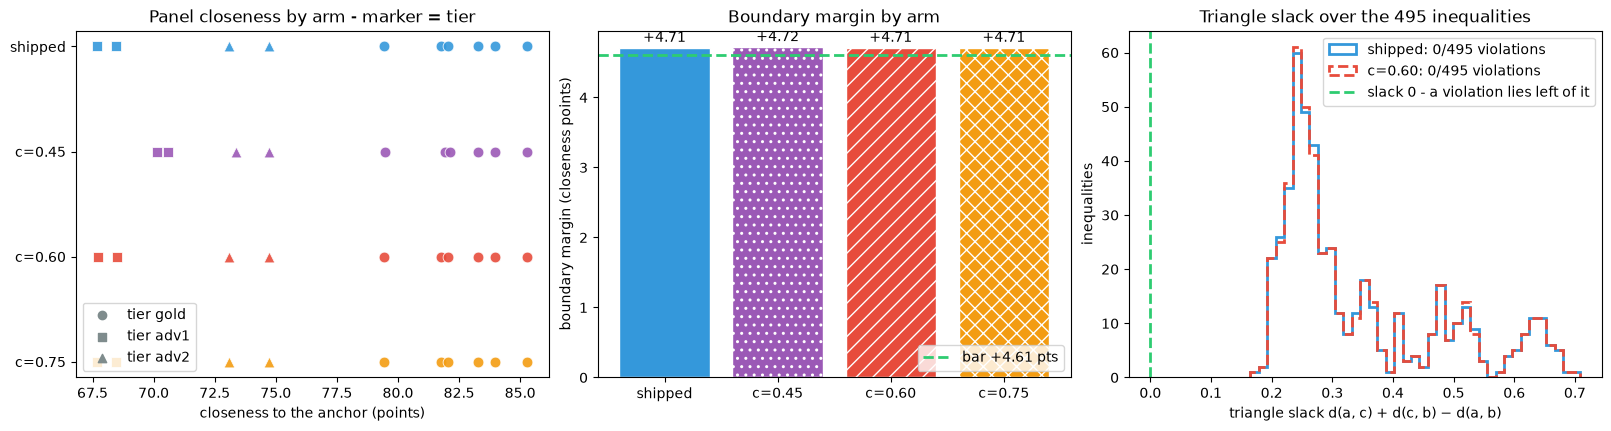

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2), constrained_layout=True)

ax = axes[0]
for row, arm in enumerate(ARMS):
    for label in NONREF:
        ax.scatter(closeness(PANEL_DIST[arm][label]) * 100, row, marker=TIER_MARKER[TIER[label]], s=60,
                   color=ARM_COLOR[arm], edgecolor="white", linewidth=0.6, alpha=0.9)
for tier, marker in TIER_MARKER.items():
    ax.scatter([], [], marker=marker, color="#7F8C8D", label=f"tier {tier}")
ax.set_yticks(range(len(ARMS)), list(ARMS))
ax.invert_yaxis()
ax.set_xlabel("closeness to the anchor (points)")
ax.set_title("Panel closeness by arm - marker = tier")
ax.legend(loc="lower left")

ax = axes[1]
margins = [PANEL[arm]["margin_pts"] for arm in ARMS]
bars = ax.bar(list(ARMS), margins, color=[ARM_COLOR[arm] for arm in ARMS], hatch=[ARM_HATCH[arm] for arm in ARMS], edgecolor="white")
ax.bar_label(bars, labels=[f"{m:+.2f}" for m in margins], padding=2)
ax.axhline(BAR_MARGIN_PTS, color=BAR_COLOR, ls="--", lw=2, label=f"bar {BAR_MARGIN_PTS:+.2f} pts")
ax.set_ylabel("boundary margin (closeness points)")
ax.set_title("Boundary margin by arm")
ax.legend(loc="lower right")

ax = axes[2]
bins = np.linspace(min(s.min() for s in SLACKS.values()) - 0.01, max(s.max() for s in SLACKS.values()) + 0.01, 40)
for arm in ("shipped", REG_ARM):
    ax.hist(SLACKS[arm], bins=bins, histtype="step", lw=2, color=ARM_COLOR[arm], ls="-" if arm == "shipped" else "--",
            label=f"{arm}: {TRIANGLE[arm]['violations']}/{TRIANGLE[arm]['n']} violations")
ax.axvline(0.0, color=BAR_COLOR, ls="--", lw=2, label="slack 0 - a violation lies left of it")
ax.set_xlabel("triangle slack d(a, c) + d(c, b) − d(a, b)")
ax.set_ylabel("inequalities")
ax.set_title("Triangle slack over the 495 inequalities")
ax.legend()
plt.show()

**At `c = 0.6` the ibm panel keeps its shipped readings: `V` 0/24, margin +4.708 (shipped +4.708), d' 4.695
(shipped 4.684), and 0 of 495 triangle violations.**

- The cap changes 8 of the 55 pair distances, by at most 0.0025; on the 10 anchor pairs the largest change is 0.0006. The record predicted about 0.003
- No shipped plan carries mass on an arc above 0.6: the largest arc cost in the 55 shipped plans is 0.5918. The capped cost of a plan is never above its shipped cost, so in the 8 changed pairs the capped solve found a cheaper plan that uses arcs above 0.6 at the price 0.6
- The smallest triangle slack is 0.1770 at `c = 0.6` and 0.1771 shipped. `min(d, c)` of a metric `d` is a metric, so the exact solve on it is a metric between statement clouds; the 495 inequalities are consistent with that
- `c = 0.75` changes none of the 55 pairs. `c = 0.45` changes 39 of 55 by up to 0.0350, with `V` 0/24, margin +4.718 and d' 5.592; it has no bar
- On summaries of one article the registered cap changes almost nothing, which is the panel part of the prediction. These readings are taken after the kill-gate and do not decide the verdict

## Registered experiment - the insertion set

Each host `B` with `n` statements receives one cross-article statement `s` at index `n // 2`, and the increment
`SMD(B, B ⊕ s)` is solved once per arm. The solve has a closed form that is checked on every insertion: the `n`
unchanged statements keep mass `1/(n+1)` in place, and each sends its surplus `1/(n(n+1))` to the inserted statement,
so

$$\mathrm{SMD}_c(B, B \oplus s) \;=\; \frac{1}{n+1}\cdot\frac{1}{n}\sum_{i=1}^{n} \min\!\big(\mathrm{cost}(b_i, s),\, c\big) \;+\; \frac{1}{n+1}\sum_{i=1}^{n}\mathrm{cost}(b_i, b_i')$$

where the last term is the float32 rounding of the cost between a statement and its own copy `b_i'`. The increment
is the mean cost from the inserted statement to all host statements, divided by `n + 1`.

In [15]:
INC = {arm: np.empty(N_INS) for arm in ARMS}  # the increment SMD(B, B + s) per insertion and arm
INPLACE = {arm: np.empty(N_INS) for arm in ARMS}  # cost of the in-place plan, the closed form above
SELF_COST = np.empty(N_INS)  # largest cost between a host statement and its own copy

with Progress(TextColumn("{task.description}"), BarColumn(), MofNCompleteColumn(), TimeElapsedColumn()) as progress:
    task = progress.add_task(f"insertions x {len(ARMS)} arms", total=N_INS)
    for k in range(N_INS):
        X = host_emb[INS["host"][k]]
        n = len(X)
        pos = n // 2
        Y = np.insert(X, pos, pool_emb[INS["pool"][k]][INS["j"][k]], axis=0)
        C = cost_matrix(X, Y)
        own = np.delete(np.arange(n + 1), pos)  # column of each host statement's own copy
        SELF_COST[k] = C[np.arange(n), own].max()
        for arm, cap in ARMS.items():
            INC[arm][k] = smd_arm(X, Y, cap)
            Cc = C if cap is None else np.minimum(C, cap)
            INPLACE[arm][k] = Cc[np.arange(n), own].sum() / (n + 1) + Cc[:, pos].sum() / (n * (n + 1))
        progress.advance(task)

In [16]:
def cv(values: np.ndarray) -> float:
    """Coefficient of variation: population std over mean."""
    return float(np.std(values) / np.mean(values))


REG_READING = "pooled, all insertions (registered)"
ALL = np.ones(N_INS, dtype=bool)
SCALE = INS["n"] + 1  # multiplying the increment by n + 1 removes the host-length factor
# reading -> (insertion mask, multiplier applied to the increment)
CV_READINGS = {
    REG_READING: (ALL, 1.0),
    DIR_IBM: (INS["direction"] == DIR_IBM, 1.0),
    DIR_WERG: (INS["direction"] == DIR_WERG, 1.0),
    "pooled, increment x (n + 1)": (ALL, SCALE),
    f"pooled, statements of {MIN_WORDS}+ words": (LONG, 1.0),
    f"statements of {MIN_WORDS}+ words, increment x (n + 1)": (LONG, SCALE),
    f"pooled, statements under {MIN_WORDS} words": (~LONG, 1.0),
}
CV = {name: {arm: cv((INC[arm] * mult)[mask]) for arm in ARMS} for name, (mask, mult) in CV_READINGS.items()}
CV_N = {name: int(mask.sum()) for name, (mask, _) in CV_READINGS.items()}
# CV of the host-length factor alone, 1/(n + 1), on the same insertions: the value a cap that removes every cost difference leaves
CV_LENGTH = {name: cv((1.0 / SCALE * mult)[mask]) for name, (mask, mult) in CV_READINGS.items()}
HOST_CV = {host: {arm: cv(INC[arm][INS["host"] == host]) for arm in ARMS} for host in HOSTS}
PER_HOST_READING = "median of the 10 per-host CVs"
CV[PER_HOST_READING] = {arm: float(np.median([HOST_CV[host][arm] for host in HOSTS])) for arm in ARMS}
CV_N[PER_HOST_READING] = len(HOSTS)
CV_LENGTH[PER_HOST_READING] = 0.0
FALL = {name: {arm: 1.0 - CV[name][arm] / CV[name]["shipped"] for arm in ARMS} for name in CV}
FALL_TO_LENGTH = {name: 1.0 - CV_LENGTH[name] / CV[name]["shipped"] for name in CV}  # the fall when only the host-length factor remains
LENGTH_TERM_CV = CV_LENGTH[REG_READING]

# increment x (n + 1) is the mean cost from the inserted statement to the n host statements (plus float32 rounding of the self-costs)
LENGTH_CLASS = {f"statements under {MIN_WORDS} words": ~LONG, f"statements of {MIN_WORDS}+ words": LONG}
MEAN_COST = {name: {arm: {stat: float(getattr((INC[arm] * SCALE)[mask], stat)()) for stat in ("mean", "min", "max")} for arm in ("shipped", REG_ARM)}
             for name, mask in LENGTH_CLASS.items()}

POOLED = {arm: {"mean": float(INC[arm].mean()), "std": float(INC[arm].std()), "cv": CV[REG_READING][arm], "cv_fall": FALL[REG_READING][arm],
                "std_fall": float(1.0 - INC[arm].std() / INC["shipped"].std()),
                "insertions_changed": int((np.abs(INC[arm] - INC["shipped"]) > FLOAT_TOL).sum())} for arm in ARMS}
CV_FALL_REG = FALL[REG_READING][REG_ARM]
INPLACE_GAP = {arm: float(np.abs(INPLACE[arm] - INC[arm]).max()) for arm in ARMS}

t1 = Table(title="CV of the increment by reading - CV, and its fall against shipped", header_style="bold slate_blue1",
           caption=f"bar: fall >= {BAR_CV_FALL:.0%} on the registered reading at {REG_ARM} - reading {CV_FALL_REG:.1%} | "
                   f"host length alone: the CV of 1/(n + 1) on the same insertions, and the fall from shipped to it")
t1.add_column("reading", style="grey70")
t1.add_column("count", justify="right")
for arm in ARMS:
    t1.add_column(arm, justify="right")
t1.add_column("host length alone", justify="right")
for name in CV:
    t1.add_row(name, str(CV_N[name]), *[f"{CV[name][arm]:.4f}" + ("" if arm == "shipped" else f" ({FALL[name][arm]:+.1%})") for arm in ARMS],
               f"{CV_LENGTH[name]:.4f} ({FALL_TO_LENGTH[name]:+.1%})")

t2 = Table(title=f"Registered reading - the {N_INS} increments pooled", header_style="bold slate_blue1",
           caption="closed form against the solver, max |difference| per arm: " + ", ".join(f"{arm} {gap:.1e}" for arm, gap in INPLACE_GAP.items())
                   + f" | largest cost between a statement and its own copy: {SELF_COST.max():.1e}")
t2.add_column("arm", style="grey70")
for col in ("mean increment", "std", "CV", "fall in CV", "fall in std", "insertions changed by the cap"):
    t2.add_column(col, justify="right")
for arm, p in POOLED.items():
    t2.add_row(arm, f"{p['mean']:.5f}", f"{p['std']:.5f}", f"{p['cv']:.4f}", "-" if arm == "shipped" else f"{p['cv_fall']:.1%}",
               "-" if arm == "shipped" else f"{p['std_fall']:.1%}", "-" if arm == "shipped" else f"{p['insertions_changed']}/{N_INS}")
t3 = Table(title="Increment x (n + 1) - the mean cost from the inserted statement to all host statements - by length of the inserted statement",
           header_style="bold slate_blue1")
t3.add_column("inserted statement", style="grey70")
t3.add_column("insertions", justify="right")
for arm in ("shipped", REG_ARM):
    for stat in ("mean", "min", "max"):
        t3.add_column(f"{arm} {stat}", justify="right")
for name, mask in LENGTH_CLASS.items():
    t3.add_row(name, str(int(mask.sum())), *[f"{MEAN_COST[name][arm][stat]:.3f}" for arm in ("shipped", REG_ARM) for stat in ("mean", "min", "max")])
console.print(Group(t1, t2, t3))

                         CV of the increment by reading - CV, and its fall against shipped                         
┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ reading             ┃ count ┃ shipped ┃          c=0.45 ┃          c=0.60 ┃          c=0.75 ┃ host length alone ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ pooled, all         │   574 │  0.3957 │ 0.0836 (+78.9%) │ 0.1189 (+70.0%) │ 0.1902 (+51.9%) │   0.0847 (+78.6%) │
│ insertions          │       │         │                 │                 │                 │                   │
│ (registered)        │       │         │                 │                 │                 │                   │
│ ibm host, wergeland │   364 │  0.3240 │ 0.0759 (+76.6%) │ 0.1052 (+67.5%) │ 0.1711 (+47.2%) │   0.0769 (+76.3%) │
│ statement           │       │         │                 │                 │                 │                   │
│ wergeland host, ibm │   210 │  0.4363 │ 0.0933 (+78.6%) │ 0.1396 (+68.0%) │ 0.2156 (+50.6%) │   0.0950 (+78.2%) │
│ statement           │       │         │                 │                 │                 │                   │
│ pooled, increment x │   574 │  0.3899 │ 0.0093 (+97.6%) │ 0.0871 (+77.7%) │ 0.1733 (+55.5%) │  0.0000 (+100.0%) │
│ (n + 1)             │       │         │                 │                 │                 │                   │
│ pooled, statements  │   420 │  0.1328 │ 0.0824 (+38.0%) │ 0.1121 (+15.6%) │  0.1327 (+0.1%) │   0.0834 (+37.2%) │
│ of 5+ words         │       │         │                 │                 │                 │                   │
│ statements of 5+    │   420 │  0.1062 │ 0.0105 (+90.1%) │ 0.0780 (+26.6%) │  0.1060 (+0.2%) │  0.0000 (+100.0%) │
│ words, increment x  │       │         │                 │                 │                 │                   │
│ (n + 1)             │       │         │                 │                 │                 │                   │
│ pooled, statements  │   154 │  0.1974 │ 0.0870 (+55.9%) │ 0.0872 (+55.8%) │ 0.0880 (+55.4%) │   0.0879 (+55.5%) │
│ under 5 words       │       │         │                 │                 │                 │                   │
│ median of the 10    │    10 │  0.3162 │ 0.0041 (+98.7%) │ 0.0745 (+76.4%) │ 0.1563 (+50.6%) │  0.0000 (+100.0%) │
│ per-host CVs        │       │         │                 │                 │                 │                   │
└─────────────────────┴───────┴─────────┴─────────────────┴─────────────────┴─────────────────┴───────────────────┘
 bar: fall >= 50% on the registered reading at c=0.60 - reading 70.0% | host length alone: the CV of 1/(n + 1) on  
                               the same insertions, and the fall from shipped to it                                
                              Registered reading - the 574 increments pooled                              
┏━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ arm     ┃ mean increment ┃     std ┃     CV ┃ fall in CV ┃ fall in std ┃ insertions changed by the cap ┃
┡━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ shipped │        0.05187 │ 0.02052 │ 0.3957 │          - │           - │                             - │
│ c=0.45  │        0.03384 │ 0.00283 │ 0.0836 │      78.9% │       86.2% │                       574/574 │
│ c=0.60  │        0.04120 │ 0.00490 │ 0.1189 │      70.0% │       76.1% │                       511/574 │
│ c=0.75  │        0.04493 │ 0.00854 │ 0.1902 │      51.9% │       58.4% │                       165/574 │
└─────────┴────────────────┴─────────┴────────┴────────────┴─────────────┴───────────────────────────────┘
closed form against the solver, max |difference| per arm: shipped 1.2e-08, c=0.45 8.5e-09, c=0.60 7.7e-09,
               c=0.75 8.5e-09 

In [17]:
PER_HOST = {}
tbl = Table(title=f"Per host - shipped against {REG_ARM}", header_style="bold slate_blue1")
tbl.add_column("host", style="grey70")
for col in ("n", "insertions", f"cheapest cost > {GATE_COST}", "shipped mean", "shipped CV", f"{REG_ARM} mean", f"{REG_ARM} CV", f"{CAP_REGISTERED}/(n + 1)"):
    tbl.add_column(col, justify="right")
for host in HOSTS:
    mask = INS["host"] == host
    n = int(INS["n"][mask][0])
    PER_HOST[host] = {"n": n, "insertions": int(mask.sum()), "share_above_gate": float((INS["cheapest"][mask] > GATE_COST).mean()),
                      "mean": {arm: float(INC[arm][mask].mean()) for arm in ARMS}, "cv": HOST_CV[host]}
    h = PER_HOST[host]
    tbl.add_row(host, str(n), str(h["insertions"]), f"{h['share_above_gate']:.1%}", f"{h['mean']['shipped']:.5f}", f"{h['cv']['shipped']:.4f}",
                f"{h['mean'][REG_ARM]:.5f}", f"{h['cv'][REG_ARM]:.4f}", f"{CAP_REGISTERED / (n + 1):.5f}")
console.print(tbl)

                                         Per host - shipped against c=0.60                                         
┏━━━━━━━━┳━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━━┓
┃        ┃    ┃            ┃  cheapest cost > ┃              ┃            ┃             ┃           ┃             ┃
┃ host   ┃  n ┃ insertions ┃              0.6 ┃ shipped mean ┃ shipped CV ┃ c=0.60 mean ┃ c=0.60 CV ┃ 0.6/(n + 1) ┃
┡━━━━━━━━╇━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━━┩
│ gold   │ 11 │         52 │            21.2% │      0.05273 │     0.3118 │     0.04555 │    0.0706 │     0.05000 │
│ gold-2 │ 13 │         52 │            17.3% │      0.04500 │     0.3164 │     0.03892 │    0.0737 │     0.04286 │
│ v1     │ 12 │         52 │            21.2% │      0.04941 │     0.3070 │     0.04256 │    0.0651 │     0.04615 │
│ v2     │ 12 │         52 │            19.2% │      0.04866 │     0.3119 │     0.04203 │    0.0722 │     0.04615 │
│ opus   │ 13 │         52 │            19.2% │      0.04537 │     0.3081 │     0.03928 │    0.0675 │     0.04286 │
│ sonnet │ 11 │         52 │            17.3% │      0.05222 │     0.3216 │     0.04516 │    0.0769 │     0.05000 │
│ haiku  │ 14 │         52 │            19.2% │      0.04162 │     0.3160 │     0.03620 │    0.0753 │     0.04000 │
│ werg-a │ 11 │         70 │            47.1% │      0.06589 │     0.4396 │     0.04560 │    0.1211 │     0.05000 │
│ werg-b │ 13 │         70 │            50.0% │      0.05750 │     0.4058 │     0.04008 │    0.0905 │     0.04286 │
│ werg-c │ 14 │         70 │            48.6% │      0.05306 │     0.4246 │     0.03696 │    0.1072 │     0.04000 │
└────────┴────┴────────────┴──────────────────┴──────────────┴────────────┴─────────────┴───────────┴─────────────┘

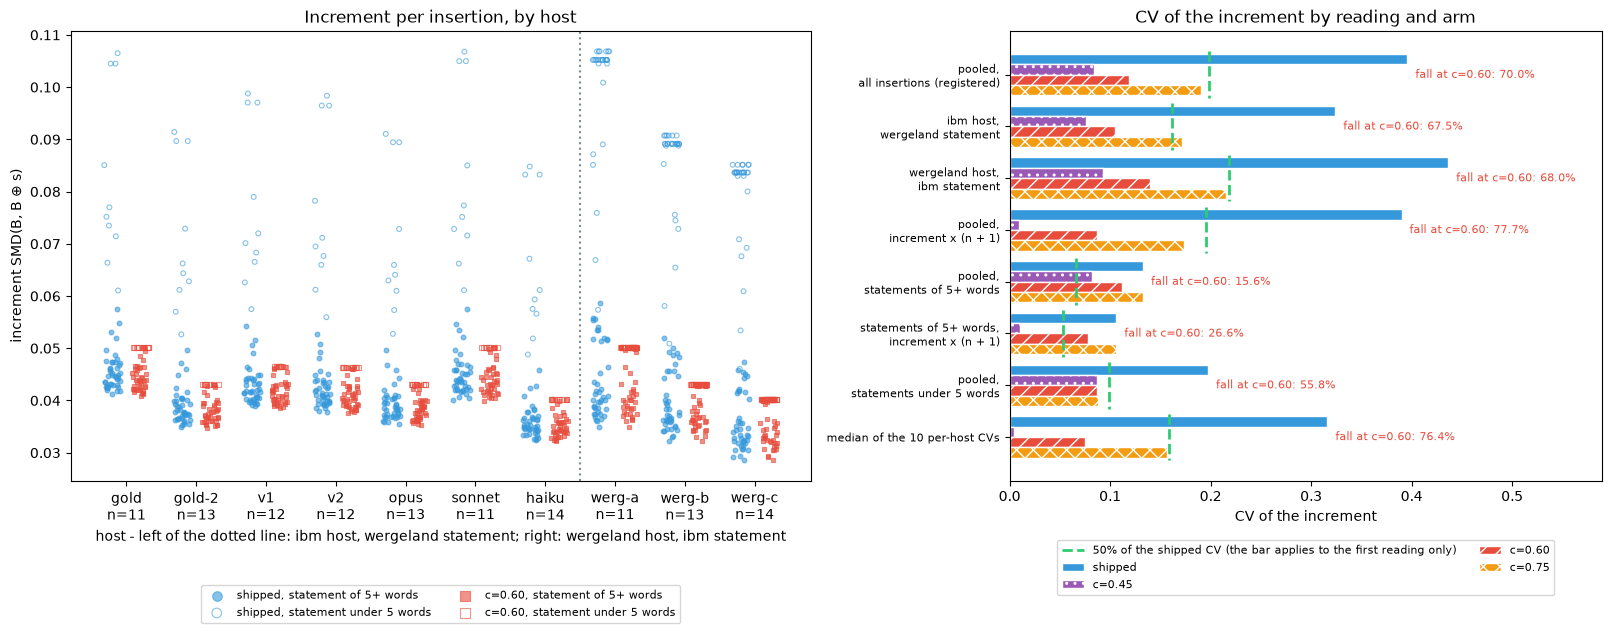

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6.2), constrained_layout=True, width_ratios=[1.25, 1])
rng = np.random.default_rng(SEED)

ax = axes[0]
for x, host in enumerate(HOSTS):
    host_mask = INS["host"] == host
    for arm, offset, marker in (("shipped", -0.2, "o"), (REG_ARM, 0.2, "s")):
        for mask, filled in ((host_mask & LONG, True), (host_mask & ~LONG, False)):
            ax.scatter(x + offset + rng.uniform(-0.12, 0.12, int(mask.sum())), INC[arm][mask], s=12, marker=marker, alpha=0.6,
                       facecolors=ARM_COLOR[arm] if filled else "none", edgecolors=ARM_COLOR[arm], linewidths=0.8,
                       label=f"{arm}, statement {'of ' + str(MIN_WORDS) + '+' if filled else 'under ' + str(MIN_WORDS)} words" if x == 0 else None)
ax.axvline(len(IBM_HOSTS) - 0.5, color="#7F8C8D", ls=":", lw=1.5)
ax.set_xticks(range(len(HOSTS)), [f"{host}\nn={PER_HOST[host]['n']}" for host in HOSTS])
ax.set_xlabel(f"host - left of the dotted line: {DIR_IBM}; right: {DIR_WERG}")
ax.set_ylabel("increment SMD(B, B ⊕ s)")
ax.set_title("Increment per insertion, by host")
ax.legend(markerscale=2, fontsize=8, ncols=2, loc="upper center", bbox_to_anchor=(0.5, -0.22))

ax = axes[1]
names = list(CV)
height = 0.8 / len(ARMS)
for a_idx, arm in enumerate(ARMS):
    ys = np.arange(len(names)) + (a_idx - (len(ARMS) - 1) / 2) * height
    ax.barh(ys, [CV[name][arm] for name in names], height=height, color=ARM_COLOR[arm], hatch=ARM_HATCH[arm], edgecolor="white", label=arm)
for y, name in enumerate(names):
    ax.vlines(CV[name]["shipped"] * (1 - BAR_CV_FALL), y - 0.45, y + 0.45, color=BAR_COLOR, ls="--", lw=2,
              label=f"{BAR_CV_FALL:.0%} of the shipped CV (the bar applies to the first reading only)" if y == 0 else None)
    ax.annotate(f"  fall at {REG_ARM}: {FALL[name][REG_ARM]:.1%}", (CV[name]["shipped"], y), ha="left", va="center", color=ARM_COLOR[REG_ARM], fontsize=8)
ax.set_yticks(range(len(names)), [name.replace(", ", ",\n", 1) for name in names], fontsize=8)
ax.invert_yaxis()
ax.set_xlim(0, max(CV[name]["shipped"] for name in names) * 1.35)
ax.set_xlabel("CV of the increment")
ax.set_title("CV of the increment by reading and arm")
ax.legend(fontsize=8, ncols=2, loc="upper center", bbox_to_anchor=(0.5, -0.12))
plt.show()

**On the registered reading the CV of the increment falls from 0.3957 to 0.1189 at `c = 0.6`, a fall of 70.0%
against the 50% bar. The fall comes from the difference between two kinds of inserted statement, not from the
sentences: on the 420 insertions of statements with 5 or more words the CV falls from 0.1328 to 0.1121, a fall of
15.6%.**

- The closed form holds on all 574 insertions (largest difference against the solver 1.2e-08): the inserted statement receives mass from every host statement, so the increment is the mean cost to all `n` host statements divided by `n + 1`, not the cost to the nearest one. The cap therefore changes 511 of 574 increments while the cheapest arc is above 0.6 in 172
- Statements under 5 words have a mean cost to the host statements of 1.097 shipped, and the cap sets it to 0.603. Statements of 5 or more words have 0.544 shipped and 0.530 capped
- The pooled shipped CV (0.3957) is larger than the CV inside either group (0.1974 under 5 words, 0.1328 for 5 or more words), so most of it is the difference between the two group means. The cap removes that difference
- The host-length factor `1/(n + 1)` alone has a CV of 0.0847 over the insertion set, and no cap changes it. On statements of 5 or more words a cap that left only that factor would give a fall of 37.2%, below the 50% bar; `c = 0.45`, which changes all 574 increments, gives 38.0%
- With the host-length factor removed (increment × (n + 1)) the fall at `c = 0.6` is 77.7% over all insertions and 26.6% over statements of 5 or more words
- The two directions agree at 67.5% and 68.0%, and the median per-host CV falls from 0.3162 to 0.0745 (76.4%)
- Without a bar: the registered reading falls 78.9% at `c = 0.45` and 51.9% at `c = 0.75`
- The registered cap makes the cost of inserted fragments and heading lines uniform. It does not halve the spread of the cost of an inserted sentence, which is the case the hypothesis describes
- These readings are taken after the kill-gate and do not decide the verdict

## Guardrails

Every standing guardrail is measured. `V` is counted on the registered arm. The no-edit guardrail compares the byte
hash of `src/` taken before the first computation with the hash now, and reads `git status` for `src/` and
`tests/`. The default path is recomputed on the 55 pairs and compared with the snapshot taken before any capped
solve and with the saved 1.1.5 baseline by `np.array_equal`. The metric property of the capped distance is read
from identity, symmetry and the 495 triangle inequalities.

In [19]:
SRC_HASH_AFTER = tree_hash(ROOT / "src")
git_dirty = subprocess.run(["git", "-C", str(ROOT), "status", "--porcelain", "--", "src", "tests"], capture_output=True, text=True, check=True).stdout.strip()

smd_after = np.array([smd(emb[a], emb[b]) for a, b in PAIRS])
gap_after = np.array([opw_gap(emb[a], emb[b]) for a, b in PAIRS])

identity_max = max(smd_capped(emb[label], emb[label], CAP_REGISTERED) for label in LABELS)
symmetry_max = float(np.abs(np.array([smd_capped(emb[b], emb[a], CAP_REGISTERED) for a, b in PAIRS]) - PAIR_DIST[REG_ARM]).max())

GUARD = {
    "V_registered_arm": f"{PANEL[REG_ARM]['V']}/24",
    "src_hash_before": SRC_HASH_BEFORE,
    "src_hash_after": SRC_HASH_AFTER,
    "src_hash_equal": bool(SRC_HASH_BEFORE == SRC_HASH_AFTER),
    "git_status_src_tests_clean": bool(git_dirty == ""),
    "default_smd_equal_before_after": bool(np.array_equal(smd_before, smd_after)),
    "default_order_gap_equal_before_after": bool(np.array_equal(gap_before, gap_after)),
    "default_smd_equal_saved_baseline": BASELINE_SMD_EQUAL,
    "default_order_gap_equal_saved_baseline": BASELINE_GAP_EQUAL,
    "wrapper_equals_shipped_at_cap_inf": WRAPPER_IDENTICAL,
    "capped_identity_max": float(identity_max),
    "capped_symmetry_max_abs_diff": symmetry_max,
    "capped_triangle_violations": f"{TRIANGLE[REG_ARM]['violations']}/{TRIANGLE[REG_ARM]['n']}",
}
SRC_UNTOUCHED = bool(GUARD["src_hash_equal"] and GUARD["git_status_src_tests_clean"])

tbl = Table(title="Guardrails, measured", header_style="bold slate_blue1")
tbl.add_column("guardrail", style="grey70")
tbl.add_column("reading", justify="right")
tbl.add_column("required", justify="right")
tbl.add_row(f"V at {REG_ARM}", GUARD["V_registered_arm"], "0/24")
tbl.add_row("src/ byte hash, before = after", f"{GUARD['src_hash_equal']} ({SRC_HASH_AFTER[:16]})", "True")
tbl.add_row("git status of src/ and tests/ is empty", str(GUARD["git_status_src_tests_clean"]), "True")
tbl.add_row("default smd, 55 pairs, before = after (np.array_equal)", str(GUARD["default_smd_equal_before_after"]), "True")
tbl.add_row("default order_gap, 55 pairs, before = after (np.array_equal)", str(GUARD["default_order_gap_equal_before_after"]), "True")
tbl.add_row("default smd = saved 1.1.5 baseline (np.array_equal)", str(GUARD["default_smd_equal_saved_baseline"]), "True")
tbl.add_row("default order_gap = saved 1.1.5 baseline (np.array_equal)", str(GUARD["default_order_gap_equal_saved_baseline"]), "True")
tbl.add_row("smd_capped at cap = inf equals shipped smd (np.array_equal)", str(GUARD["wrapper_equals_shipped_at_cap_inf"]), "True")
tbl.add_row(f"capped identity, max d(A, A) over {len(LABELS)} documents", f"{GUARD['capped_identity_max']:.1e}", "0")
tbl.add_row(f"capped symmetry, max |d(A, B) − d(B, A)| over {len(PAIRS)} pairs", f"{GUARD['capped_symmetry_max_abs_diff']:.1e}", "float rounding")
tbl.add_row("capped triangle violations", GUARD["capped_triangle_violations"], "0/495")
console.print(tbl)

                                           Guardrails, measured                                            
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┓
┃ guardrail                                                    ┃                 reading ┃       required ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━┩
│ V at c=0.60                                                  │                    0/24 │           0/24 │
│ src/ byte hash, before = after                               │ True (a5932434475fda56) │           True │
│ git status of src/ and tests/ is empty                       │                    True │           True │
│ default smd, 55 pairs, before = after (np.array_equal)       │                    True │           True │
│ default order_gap, 55 pairs, before = after (np.array_equal) │                    True │           True │
│ default smd = saved 1.1.5 baseline (np.array_equal)          │                    True │           True │
│ default order_gap = saved 1.1.5 baseline (np.array_equal)    │                    True │           True │
│ smd_capped at cap = inf equals shipped smd (np.array_equal)  │                    True │           True │
│ capped identity, max d(A, A) over 11 documents               │                 0.0e+00 │              0 │
│ capped symmetry, max |d(A, B) − d(B, A)| over 55 pairs       │                 2.2e-16 │ float rounding │
│ capped triangle violations                                   │                   0/495 │          0/495 │
└──────────────────────────────────────────────────────────────┴─────────────────────────┴────────────────┘

**All standing guardrails hold: `V` is 0/24 at `c = 0.6`, the byte hash of `src/` is equal before and after the
run, and `git status` reports no change under `src/` or `tests/`.**

- The default-path `smd` and `order_gap` on the 55 pairs are equal before and after the capped solves by `np.array_equal`, and equal to the saved 1.1.5 baseline
- `smd_capped` with the cap at infinity returns the shipped `smd` on all 55 pairs, so the wrapper differs from the shipped solve by the one `np.minimum`
- The capped distance is 0 on the 11 identity pairs, symmetric to 2.2e-16, and has 0 of 495 triangle violations
- The shipped distance and its metric property are untouched: the capped distance exists only in this notebook

## Verdict

The registered acceptance bar, applied as written: PASS iff `V = 0/24` AND boundary margin `>= +4.61` closeness
points AND triangle violations `0/495` AND the CV of the increment falls `>= 50%` against shipped, all at
`c = 0.6`. The order of the decision is the stage A contract: a kill-gate that does not pass gives
`Killed-at-gate`, a failed sanity check gives `Blocked`, a met bar gives `Promoted`, a bar that is not met gives
`Refuted`.

In [20]:
reg = PANEL[REG_ARM]
BAR = {
    "V": {"reading": f"{reg['V']}/24", "required": f"{BAR_V}/24", "met": bool(reg["V"] == BAR_V)},
    "margin_pts": {"reading": round(reg["margin_pts"], 3), "required": f">= {BAR_MARGIN_PTS:+.2f}", "met": bool(reg["margin_pts"] >= BAR_MARGIN_PTS)},
    "triangle": {"reading": f"{TRIANGLE[REG_ARM]['violations']}/{TRIANGLE[REG_ARM]['n']}", "required": f"{BAR_TRIANGLE}/495",
                 "met": bool(TRIANGLE[REG_ARM]["violations"] == BAR_TRIANGLE and TRIANGLE[REG_ARM]["n"] == 495)},
    "cv_fall": {"reading": round(CV_FALL_REG, 4), "required": f">= {BAR_CV_FALL:.2f}", "met": bool(CV_FALL_REG >= BAR_CV_FALL)},
}
BAR_MET = all(item["met"] for item in BAR.values())

if not GATE_PASSED:
    VERDICT = "Killed-at-gate"
elif not SANITY_OK:
    VERDICT = "Blocked"
elif BAR_MET:
    VERDICT = "Promoted"
else:
    VERDICT = "Refuted"

RESULT_NUMBERS = {
    "kill_gate_share_above_0.6": round(GATE_SHARE, 4),
    "kill_gate_n_above": GATE[GATE_READING]["n_above"],
    "n_insertions": N_INS,
    "kill_gate_share_by_reading": {name: f"{g['n_above']}/{g['n']} = {g['share']:.1%}" for name, g in GATE.items()},
    "kill_gate_median_cheapest_cost": round(GATE[GATE_READING]["median"], 3),
    "sanity_margin_pts": round(BASE["margin_pts"], 3),
    "sanity_dprime": round(BASE["dprime"], 3),
    "sanity_V": f"{BASE['V']}/24",
    "capped_V": f"{reg['V']}/24",
    "capped_margin_pts": round(reg["margin_pts"], 3),
    "capped_dprime": round(reg["dprime"], 3),
    "capped_max_abs_delta_smd_55_pairs": round(reg["max_abs_delta_pairs"], 4),
    "capped_max_abs_delta_smd_anchor_pairs": round(reg["max_abs_delta_anchor"], 4),
    "capped_pairs_changed": f"{reg['pairs_changed']}/{len(PAIRS)}",
    "shipped_plan_max_arc": round(float(plan_max_arc.max()), 4),
    "triangle_violations": f"{TRIANGLE[REG_ARM]['violations']}/{TRIANGLE[REG_ARM]['n']}",
    "triangle_min_slack": round(TRIANGLE[REG_ARM]["min_slack"], 4),
    "cv_shipped_pooled": round(CV[REG_READING]["shipped"], 4),
    "cv_capped_pooled": round(CV[REG_READING][REG_ARM], 4),
    "cv_fall_pooled_registered": round(CV_FALL_REG, 4),
    "cv_of_host_length_term": round(LENGTH_TERM_CV, 4),
    "cv_by_reading": {name: {arm: round(CV[name][arm], 4) for arm in ARMS} for name in CV},
    "cv_host_length_alone_by_reading": {name: round(CV_LENGTH[name], 4) for name in CV},
    "cv_fall_to_host_length_alone_by_reading": {name: round(FALL_TO_LENGTH[name], 4) for name in CV},
    "mean_cost_to_host_statements": {name: {arm: round(MEAN_COST[name][arm]["mean"], 3) for arm in MEAN_COST[name]} for name in MEAN_COST},
    "cv_fall_by_reading_at_registered_arm": {name: round(FALL[name][REG_ARM], 4) for name in CV},
    "cv_fall_pooled_by_arm": {arm: round(FALL[REG_READING][arm], 4) for arm in ARMS if arm != "shipped"},
    "std_fall_pooled_registered": round(POOLED[REG_ARM]["std_fall"], 4),
    "insertions_changed_by_cap": f"{POOLED[REG_ARM]['insertions_changed']}/{N_INS}",
}

tbl = Table(title=f"E13-H72 acceptance bar at {REG_ARM}", header_style="bold slate_blue1",
            caption=f"kill-gate {'passed' if GATE_PASSED else 'not passed'} ({GATE_SHARE:.1%} against >= {GATE_MIN_SHARE:.0%}) | "
                    f"sanity check {'passed' if SANITY_OK else 'failed'} | the four bar conditions: {'all met' if BAR_MET else 'not all met'} | "
                    f"the kill-gate is decided before the bar | verdict: {VERDICT}")
tbl.add_column("condition", style="grey70")
tbl.add_column("reading", justify="right")
tbl.add_column("required", justify="right")
tbl.add_column("met")
for name, item in BAR.items():
    tbl.add_row(name, str(item["reading"]), item["required"], f"[{'dark_sea_green' if item['met'] else 'indian_red'}]{item['met']}[/]")
console.print(tbl)

     E13-H72 acceptance bar at c=0.60     
┏━━━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━┳━━━━━━┓
┃ condition  ┃ reading ┃ required ┃ met  ┃
┡━━━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━╇━━━━━━┩
│ V          │    0/24 │     0/24 │ True │
│ margin_pts │   4.708 │ >= +4.61 │ True │
│ triangle   │   0/495 │    0/495 │ True │
│ cv_fall    │  0.6995 │  >= 0.50 │ True │
└────────────┴─────────┴──────────┴──────┘
  kill-gate not passed (30.0% against >=  
50%) | sanity check passed | the four bar 
  conditions: all met | the kill-gate is  
    decided before the bar | verdict:     
              Killed-at-gate              

In [21]:
# the numbers the stage A result quotes, at the rounding it uses
print(json.dumps(RESULT_NUMBERS, indent=1, ensure_ascii=False))

{
 "kill_gate_share_above_0.6": 0.2997,
 "kill_gate_n_above": 172,
 "n_insertions": 574,
 "kill_gate_share_by_reading": {
  "ibm host, wergeland statement": "70/364 = 19.2%",
  "wergeland host, ibm statement": "102/210 = 48.6%",
  "all insertions (the gate reading)": "172/574 = 30.0%",
  "statements of 5+ words (no bar)": "22/420 = 5.2%",
  "statements under 5 words (no bar)": "150/154 = 97.4%",
  "ibm hosts segmented on the shipped path (no bar)": "186/574 = 32.4%",
  "unique statements, above in at least one host (no bar)": "48/122 = 39.3%"
 },
 "kill_gate_median_cheapest_cost": 0.489,
 "sanity_margin_pts": 4.708,
 "sanity_dprime": 4.684,
 "sanity_V": "0/24",
 "capped_V": "0/24",
 "capped_margin_pts": 4.708,
 "capped_dprime": 4.695,
 "capped_max_abs_delta_smd_55_pairs": 0.0025,
 "capped_max_abs_delta_smd_anchor_pairs": 0.0006,
 "capped_pairs_changed": "8/55",
 "shipped_plan_max_arc": 0.5918,
 "triangle_violations": "0/495",
 "triangle_min_slack": 0.177,
 "cv_shipped_pooled": 0.3957,


## Save

Writes every measured number, the bar readings and the guardrail readings to the metrics file. No figure is
written to disk.

In [22]:
metrics = {
    "id": "E13-H72",
    "slug": "capped-ground-cost",
    "date": "2026-10-09",
    "versions": VERSIONS,
    "config": {
        "cap_registered": CAP_REGISTERED, "caps_unbarred": list(CAPS_UNBARRED), "gate_cost": GATE_COST, "gate_min_share": GATE_MIN_SHARE,
        "sanity_row": SANITY_ROW, "sanity_rel_tol": SANITY_REL_TOL,
        "bar": {"V": BAR_V, "margin_pts": BAR_MARGIN_PTS, "triangle_violations": BAR_TRIANGLE, "cv_fall": BAR_CV_FALL},
        "float_tol": FLOAT_TOL, "min_words_unbarred_reading": MIN_WORDS, "insert_position": "n // 2", "cv": "population std / mean",
    },
    "fixture": {
        "panel_statements": {label: int(len(emb[label])) for label in LABELS},
        "host_statements": {host: int(len(host_emb[host])) for host in HOSTS},
        "pool_statements": {name: int(len(pool_sents[name])) for name in pool_sents},
        "pool_statements_min_words": {name: int(sum(len(text.split()) >= MIN_WORDS for text in pool_sents[name])) for name in pool_sents},
        "n_insertions": N_INS,
    },
    "kill_gate": {"readings": GATE, "share": GATE_SHARE, "passed": GATE_PASSED, "statements_under_min_words": SHORT_TEXTS},
    "sanity_check": {"measured": BASE, "registered": SANITY_ROW, "relative_deviation": SANITY_DEV, "passed": SANITY_OK},
    "panel": {arm: {**PANEL[arm], "dist_to_anchor": PANEL_DIST[arm], "closeness_to_anchor": {label: closeness(d) for label, d in PANEL_DIST[arm].items()}}
              for arm in ARMS},
    "shipped_plan_max_arc": float(plan_max_arc.max()),
    "triangle": TRIANGLE,
    "insertion": {
        "cv": CV, "cv_count": CV_N, "cv_fall": FALL, "cv_host_length_alone": CV_LENGTH, "cv_fall_to_host_length_alone": FALL_TO_LENGTH, "mean_cost_to_host_statements": MEAN_COST, "pooled": POOLED, "per_host": PER_HOST,
        "host_length_term_cv": LENGTH_TERM_CV, "closed_form_max_abs_diff": INPLACE_GAP, "self_cost_max": float(SELF_COST.max()),
    },
    "guardrails": {**GUARD, "src_untouched": SRC_UNTOUCHED},
    "acceptance": {"bar": BAR, "met": BAR_MET},
    "verdict": VERDICT,
    "result_numbers": RESULT_NUMBERS,
}
METRICS_FILE.write_text(json.dumps(metrics, indent=1, ensure_ascii=False) + "\n", encoding="utf-8")
print(f"wrote {METRICS_FILE.relative_to(ROOT)} ({METRICS_FILE.stat().st_size} bytes)")

wrote reports/E13-H72-capped-ground-cost-metrics.json (23250 bytes)


## Conclusions

**Verdict: `Killed-at-gate`.** 172 of the 574 cross-article insertions (30.0%) have a cheapest cost to the host
above 0.6; the record requires at least 50%.

- The kill-gate reading stays below 50% under every convention measured: 19.2% and 48.6% by direction, 5.2% on statements of 5 or more words, 32.4% with the ibm hosts segmented on the shipped path, 39.3% per unique statement
- The harness sanity check passed: `V` 0/24, margin +4.708 (−0.04%), d' 4.684 (+0.09%)
- The four bar conditions, measured after the gate at `c = 0.6`, all hold on the registered reading: `V` 0/24, margin +4.708 against +4.61, triangle 0/495, CV fall 70.0% against 50%. The kill-gate is decided before the bar, so they do not change the verdict
- The 70.0% is produced by statements under 5 words (markup tokens, heading lines, pieces of a provenance comment), which the shipped default segmentation returns for a markdown source. Their mean cost to the host statements is 1.097 and the cap sets it to 0.603; for statements of 5 or more words it is 0.544 and the cap sets it to 0.530
- Over statements of 5 or more words the CV fall at `c = 0.6` is 15.6%, and 26.6% with the host-length factor removed. The prediction of a fall above 50% does not hold for inserted sentences
- The gate and the bar measure different arcs. The gate takes the cheapest arc of the inserted statement; the increment is the mean over all arcs to the host, divided by `n + 1`. This is why the cap changes 511 of 574 increments while the gate counts 172
- The ibm panel keeps its readings under the registered cap: 8 of 55 pair distances change, by at most 0.0025, with `V` 0/24 and no triangle violation
- Effect on the campaign: this record gives no promoted lever. On these two articles a 0.6 cap changes the cost of an inserted sentence by little (mean cost to the host statements 0.544 → 0.530) and acts mainly on fragment statements
- Limits: one pair of articles, both about artificial intelligence; 10 hosts of 11 to 14 statements; the insertion pool mixes sentences with fragments because the sources are markdown files read with `markdown=False`; the 5-word split is a convention of this notebook, fixed before scoring, not a registered quantity